<a href="https://colab.research.google.com/github/falcon23nk/collab-project/blob/main/Practica_1_TeachableMachine_memoria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 1 — Teachable Machine
## Clasificador de imágenes: ¿teclado o botella?

**Alumno:** (Noussayr Kordass) · **Asignatura:** IA · **Curso:** 2026/27

Memoria de la práctica: entrenamiento de un modelo propio de visión por ordenador con
Teachable Machine y su integración en una aplicación web con TensorFlow.js.

---
## 1. Objetivo y planteamiento

El encargo pide entrenar un modelo de imágenes con **al menos dos categorías**, exportarlo en
formato **TensorFlow.js** y montar con él una página web local que funcione sin depender de
Teachable Machine.

He elegido dos objetos que tengo en mi mesa de trabajo y que son fáciles de fotografiar desde
muchos ángulos:

| Clase | Objeto concreto |
|---|---|
| **Teclado** | teclado mecánico Newskill Serike TKL con retroiluminación RGB |
| **Botella** | botella de agua de 33 cl de Solán de Cabras, de plástico azul |

Son objetos muy distintos en forma y color, así que esperaba que el modelo los separase bien
incluso con pocas imágenes. La parte interesante no era tanto acertar como ver **cuándo deja de
acertar**: qué pasa si le enseño algo que no es ninguno de los dos.

---
## 2. Toma de imágenes

Hice las fotos con el móvil, sobre la misma mesa y con luz artificial. Para que el modelo
aprendiese el **objeto** y no una vista concreta, cambié el ángulo en cada foto:

| Clase | Fotos | Vistas utilizadas |
|---|---|---|
| Teclado | 6 | cenital completa, en diagonal, de perfil sujeto con la mano, la base con la etiqueta *SERIKE TKL*, y dos vistas en escorzo |
| Botella | 6 | etiqueta frontal, parte trasera con el código de barras, tapón visto desde arriba, base vista desde abajo, y dos de lado |

**Galería completa de las 12 imágenes de entrenamiento** (arriba teclado, abajo botella):

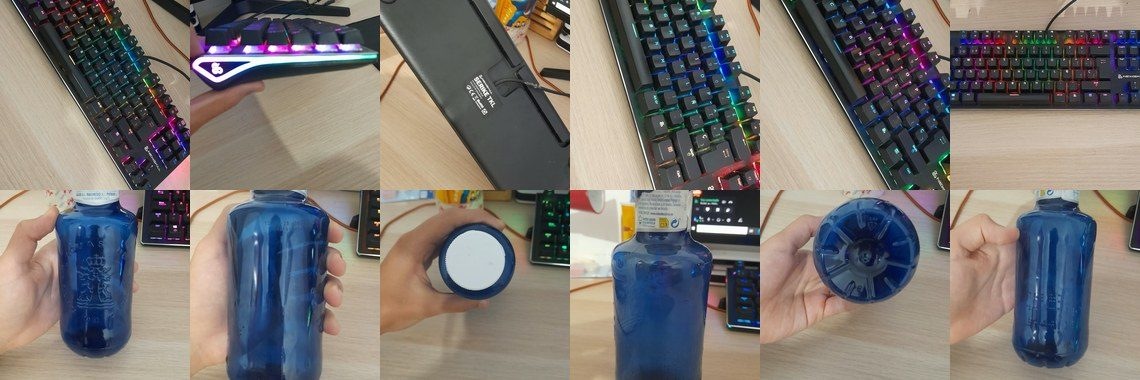

Dos decisiones que tomé aquí y que luego se notaron:

- **Fondo siempre igual.** Todas las fotos comparten la misma mesa de madera clara. Es cómodo,
  pero hace que parte de lo que aprende el modelo sea el fondo, no el objeto.
- **Incluir vistas raras.** La base del teclado y el tapón de la botella no se parecen nada a la
  vista típica de cada objeto. Las metí a propósito para que el modelo no dependa de una sola
  silueta.

---
## 3. Creación y entrenamiento del modelo

Pasos seguidos en [teachablemachine.withgoogle.com](https://teachablemachine.withgoogle.com/):

1. **Nuevo proyecto → Proyecto de imagen → Modelo de imagen estándar.**
2. Renombrar las dos clases por defecto como **Botella** y **Teclado**.
3. En cada clase, botón **Subir** → seleccionar las 6 fotos correspondientes.
4. Botón **Preparar modelo** y esperar a que termine.
5. Comprobar el resultado en el panel **Vista previa** antes de exportar.

### Qué hace por dentro

Teachable Machine no entrena una red desde cero. Parte de **MobileNet**, una red ya entrenada con
millones de imágenes, le quita la última capa y entrena solo esa última capa con mis fotos.
A esto se le llama *transfer learning* y es la razón de que 12 imágenes basten y de que el
entrenamiento dure segundos en lugar de horas.

Parámetros que deja tocar (yo dejé los valores por defecto):

| Parámetro | Valor | Para qué sirve |
|---|---|---|
| Épocas | 50 | cuántas veces repasa todas las imágenes |
| Tamaño de lote | 16 | cuántas imágenes mira de golpe |
| Tasa de aprendizaje | 0,001 | cuánto corrige en cada paso

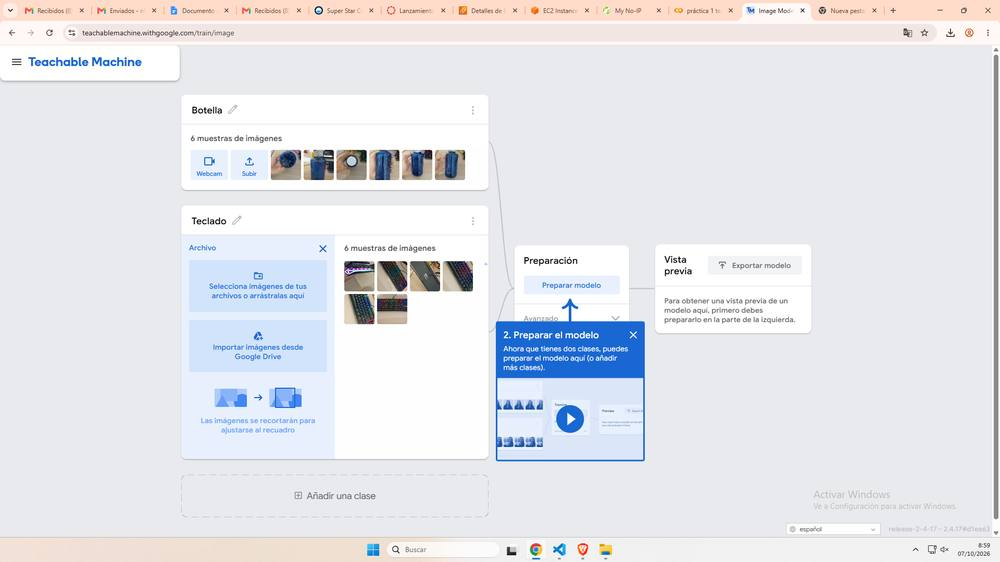

*Las dos clases con sus 6 imágenes cada una, listas para entrenar.*


---
## 4. Exportación del modelo

Desde **Exportar modelo → TensorFlow.js → Descargar mi modelo** se obtiene un zip con tres
archivos, que son los únicos que necesita la web:

| Archivo | Contenido |
|---|---|
| `model.json` | la arquitectura de la red y el índice de los pesos |
| `weights.bin` | los pesos aprendidos, en binario |
| `metadata.json` | nombres de las clases (`["Teclado","Botella"]`) y tamaño de entrada (224 × 224 px) |

También he exportado el modelo en formato **TensorFlow / Keras** (`keras.h5`), que hará falta
para una práctica posterior.

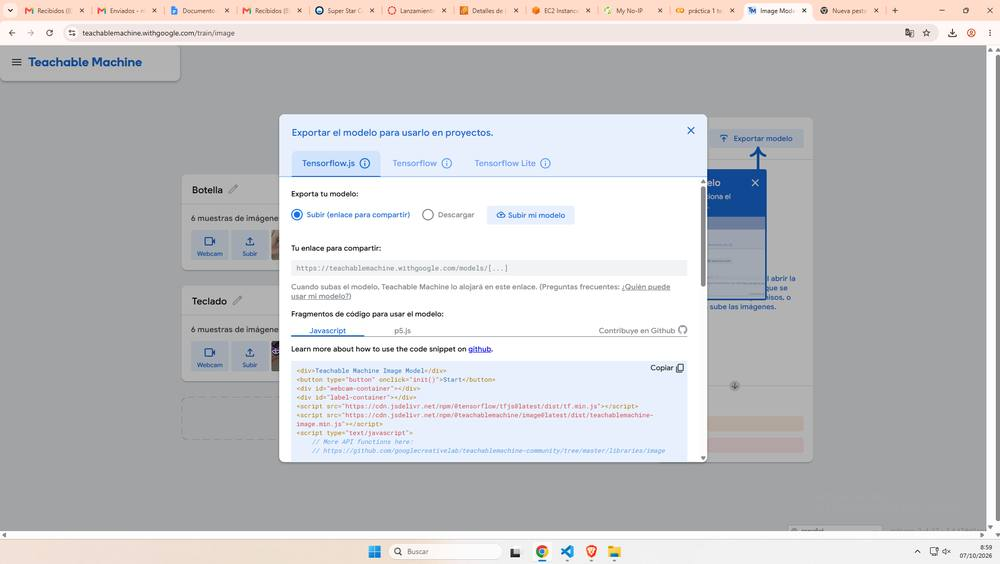

*Ventana de exportación, pestaña Tensorflow.js.*


---
## 5. La aplicación web

### Estructura de carpetas

```
clasificador/
├── index.html      estructura de la página
├── styles.css      todos los estilos
├── app.js          lógica: carga del modelo, cámara, predicción e histórico
└── modelo/
    ├── model.json
    ├── metadata.json
    └── weights.bin
```

El HTML, el CSS y el JavaScript están en archivos separados, como pedía el enunciado, en lugar
de todo mezclado en un único `index.html`.

### Aspecto final

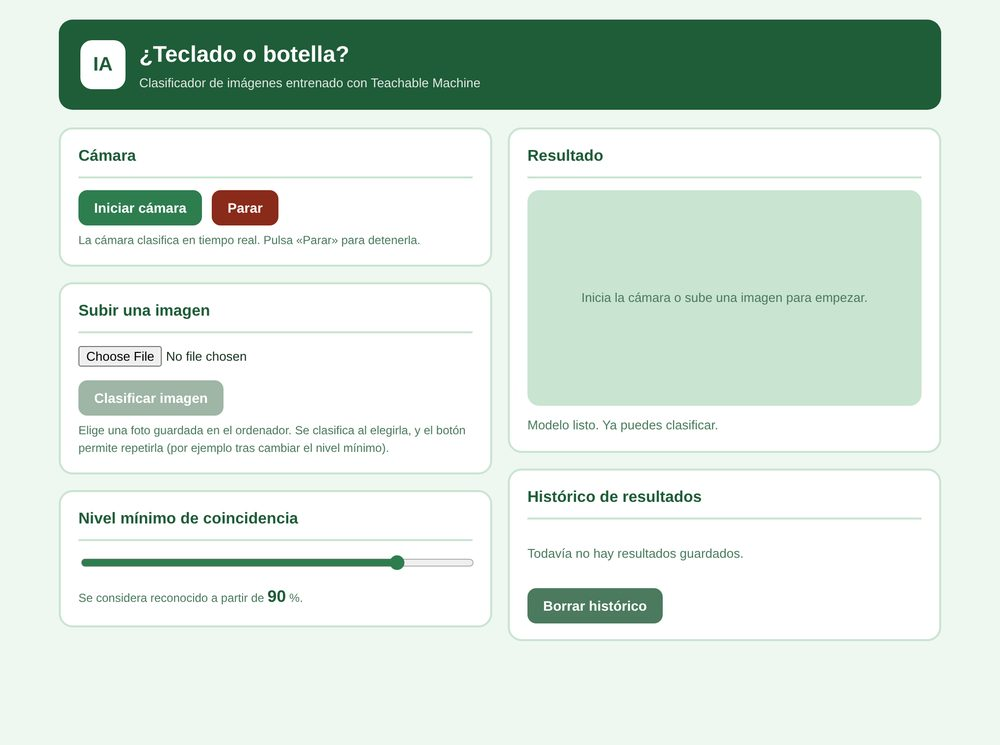

### Versión móvil

La hoja de estilos tiene un punto de ruptura en 760 px: por debajo de esa anchura las dos
columnas pasan a una sola, los botones ocupan todo el ancho y la tabla del histórico reduce la
letra. La página no produce scroll horizontal ni siquiera a 390 px.

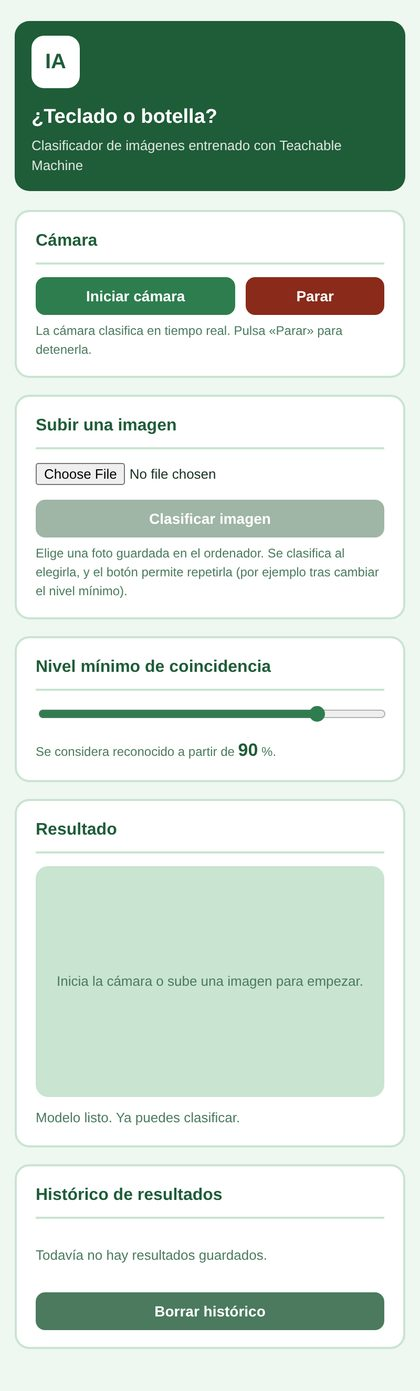

---
## 6. Mejoras implementadas

El enunciado pide una serie de mejoras una vez que el modelo funciona. Esto es lo que hace cada
una y dónde está resuelta:

| Mejora pedida | Cómo la he resuelto |
|---|---|
| Mejorar el diseño | Paleta verde propia, tarjetas separadas por función, barras de progreso para los porcentajes y un bloque de veredicto con color según el resultado. |
| Página responsive | Rejilla de dos columnas que colapsa a una en pantallas estrechas (`@media (max-width:760px)`), botones flexibles y tabla con scroll propio. |
| Botón de inicio y de parada | «Iniciar cámara» arranca la webcam y clasifica en tiempo real; «Parar» detiene el bucle y apaga la cámara. Cada botón se desactiva cuando no procede, para que no se pueda arrancar dos veces. |
| Mensaje personalizado de salida | Al parar la cámara no se queda en blanco: muestra una despedida que recuerda **lo último que reconoció**, o avisa de que no llegó a reconocer nada con seguridad. |
| Valor mínimo ajustable | Barra deslizante de 50 % a 99 %. Al moverla, el veredicto que hay en pantalla **se recalcula al instante**, sin tener que volver a subir la imagen. |
| Histórico de resultados | Tabla con hora, origen (imagen o cámara), clase, confianza y resultado. Guarda los 20 últimos en `localStorage`, así que **sobrevive al recargar la página**. Hay un botón para borrarlo. |
| Subir una imagen | Selector de archivos que clasifica cualquier foto del ordenador; si la cámara estaba encendida, se apaga sola antes de analizarla. |

### Detalle: el umbral de coincidencia

El modelo siempre reparte el 100 % entre las dos clases, incluso si le enseñas un gato. Sin un
mínimo, cualquier objeto sería clasificado como teclado o como botella. Por eso la web solo da
una respuesta cuando la clase ganadora supera el umbral:

| Salida del modelo | Umbral | Lo que muestra la web |
|---|---|---|
| Teclado 100 %, Botella 0 % | 90 % | Reconocido: es un teclado |
| Botella 56,8 %, Teclado 43,2 % | 90 % | Sin coincidencia clara: no llega al 90 % exigido |
| Botella 56,8 %, Teclado 43,2 % | 55 % | Reconocido: es una botella |

Las dos últimas filas son la misma imagen: lo único que cambia es el nivel exigido.

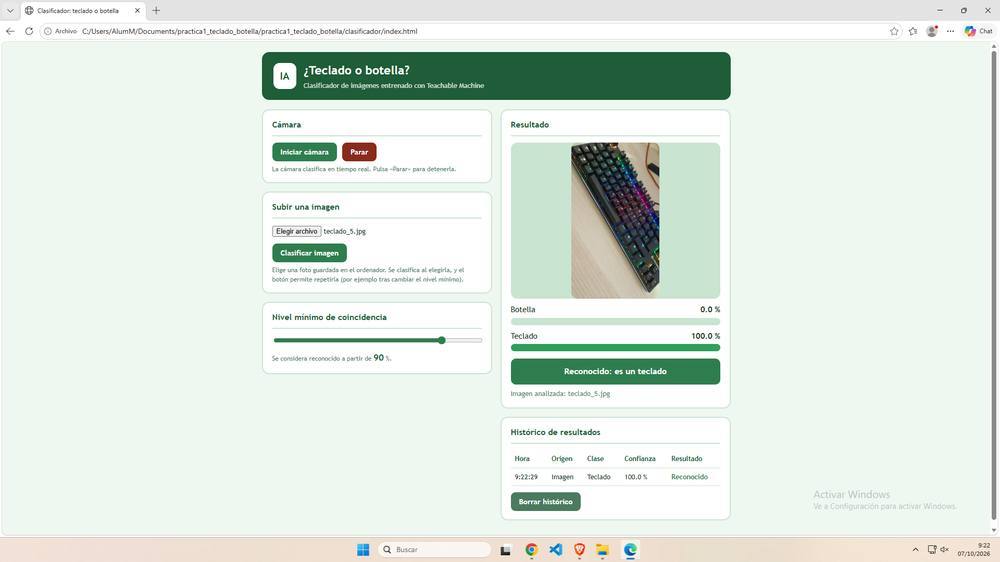

*La aplicación reconociendo el teclado con un 100 % de confianza.*

---
## 7. Cómo ejecutarla en local

Las páginas abiertas con doble clic usan el protocolo `file://`, y el navegador **prohíbe leer
archivos sueltos** desde ahí por seguridad, así que el modelo no cargaría. Lo correcto es
levantar un servidor local dentro de la carpeta:

```bash
cd clasificador
python -m http.server 8000
```

Y abrir `http://localhost:8000` en el navegador.

Aun así, previendo ese problema, la página tiene un plan B: si no consigue leer la carpeta
`modelo/`, muestra un selector para cargar los tres archivos a mano, y entonces funciona
también abriéndola con doble clic. La cámara, en cambio, sí necesita `localhost` o `https`.

---
## 8. Pruebas realizadas

| Prueba | Resultado |
|---|---|
| Carga del modelo real exportado de Teachable Machine | Correcta |
| Clasificar `teclado_5.jpg` | **Teclado 100,0 %** — reconocido |
| Clasificar una imagen subida | Correcta, con porcentajes y veredicto |
| Mover el umbral con un resultado en pantalla | El veredicto se recalcula sin reclasificar |
| Iniciar cámara | Vídeo en marcha y predicción en tiempo real |
| Parar cámara | Se detiene, aparece el mensaje de despedida y se guarda el último resultado |
| Histórico tras recargar la página | Se mantiene |
| Botón de borrar histórico | Vacía la tabla |
| Anchura de 390 px | Una sola columna y sin scroll horizontal |
| Errores en la consola | Ninguno |

---
## 9. Conclusiones

Lo que más me ha sorprendido es que con **doce fotos** el modelo ya separe los dos objetos.
La clave no es la cantidad de imágenes, sino que MobileNet ya sabía reconocer formas, bordes y
texturas antes de ver ninguna foto mía; yo solo he entrenado la última capa.

También he visto sus límites:

- Como todas las fotos están hechas sobre la misma mesa, **parte de lo que aprende es el fondo**.
  Con fotos en otros sitios y con otra luz sería más fiable.
- El modelo **nunca dice «no lo sé»** por su cuenta: siempre reparte el 100 %. Esa decisión hay
  que tomarla fuera, y es exactamente lo que hace el umbral de la web.

Mejoras que se podrían añadir más adelante: una tercera clase de *otros objetos* para que el
modelo aprenda a descartar, y exportar el histórico a CSV.

---
## 10. Código fuente

### `index.html`

```html
<!DOCTYPE html>
<html lang="es">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<title>Clasificador: teclado o botella</title>
<link rel="stylesheet" href="styles.css">
</head>
<body>

<div class="contenedor">

  <div class="cabecera">
    <span class="icono">IA</span>
    <div>
      <h1>&iquest;Teclado o botella?</h1>
      <p>Clasificador de im&aacute;genes entrenado con Teachable Machine</p>
    </div>
  </div>

  <div class="rejilla">

    <!-- ---------- Columna izquierda: entrada ---------- -->
    <div>
      <div class="panel">
        <h2>C&aacute;mara</h2>
        <div class="botones">
          <button id="btnIniciar">Iniciar c&aacute;mara</button>
          <button id="btnParar" class="parar" disabled>Parar</button>
        </div>
        <p class="ayuda">La c&aacute;mara clasifica en tiempo real. Pulsa &laquo;Parar&raquo; para detenerla.</p>
      </div>

      <div class="panel" style="margin-top:16px">
        <h2>Subir una imagen</h2>
        <input type="file" id="inputImagen" accept="image/*">
        <div class="botones" style="margin-top:12px">
          <button id="btnClasificar" disabled>Clasificar imagen</button>
        </div>
        <p class="ayuda">Elige una foto guardada en el ordenador. Se clasifica al elegirla,
          y el bot&oacute;n permite repetirla (por ejemplo tras cambiar el nivel m&iacute;nimo).</p>
      </div>

      <div class="panel" style="margin-top:16px">
        <h2>Nivel m&iacute;nimo de coincidencia</h2>
        <input type="range" id="umbral" min="50" max="99" value="90" step="1">
        <p class="ayuda">Se considera reconocido a partir de
          <span class="umbral-valor" id="umbralTexto">90</span> %.</p>
      </div>

      <div class="panel" style="margin-top:16px" id="panelModelo">
        <h2>Modelo</h2>
        <p class="ayuda" id="ayudaModelo">Cargando el modelo de la carpeta <code>modelo/</code>...</p>
        <input type="file" id="inputModelo" multiple accept=".json,.bin" hidden>
      </div>
    </div>

    <!-- ---------- Columna derecha: resultado ---------- -->
    <div>
      <div class="panel">
        <h2>Resultado</h2>
        <div class="lienzo" id="lienzo">
          <div class="vacio">Inicia la c&aacute;mara o sube una imagen para empezar.</div>
        </div>
        <div id="barras"></div>
        <div id="veredicto"></div>
        <p class="estado" id="estado">Preparando el modelo...</p>
      </div>

      <div class="panel" style="margin-top:16px">
        <h2>Hist&oacute;rico de resultados</h2>
        <div id="historico"><p class="historico-vacio">Todav&iacute;a no hay resultados guardados.</p></div>
        <div class="botones" style="margin-top:12px">
          <button id="btnBorrar" class="secundario">Borrar hist&oacute;rico</button>
        </div>
      </div>
    </div>

  </div>
</div>

<script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@1.3.1/dist/tf.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@0.8.5/dist/teachablemachine-image.min.js"></script>
<script src="app.js"></script>
</body>
</html>

```

### `styles.css`

```css
/* ---- Clasificador Teclado / Botella ---- */
:root{
  --verde-fuerte:#1f5c38;
  --verde:#2e7d4f;
  --verde-claro:#2e9e5b;
  --verde-suave:#c9e4d1;
  --fondo:#eef7f0;
  --panel:#ffffff;
  --texto:#16301f;
  --rojo:#8a2a1a;
  --rojo-suave:#f6dcd6;
}

*{box-sizing:border-box}

body{
  margin:0;
  padding:20px 14px 40px;
  background:var(--fondo);
  color:var(--texto);
  font-family:'Trebuchet MS',Verdana,Geneva,sans-serif;
  line-height:1.5;
}

.contenedor{max-width:900px;margin:0 auto}

/* ---- Cabecera ---- */
.cabecera{
  display:flex;align-items:center;gap:14px;flex-wrap:wrap;
  background:var(--verde-fuerte);color:#fff;
  border-radius:14px;padding:18px 22px;margin-bottom:18px;
}
.cabecera .icono{
  background:#fff;color:var(--verde-fuerte);font-weight:bold;font-size:20px;
  border-radius:12px;padding:10px 13px;
}
.cabecera h1{margin:0;font-size:23px}
.cabecera p{margin:2px 0 0;font-size:13px;opacity:.85}

/* ---- Rejilla ---- */
.rejilla{display:grid;grid-template-columns:1fr 1fr;gap:16px;align-items:start}
/* evita que una tabla ancha estire la columna y saque scroll lateral */
.rejilla > *{min-width:0}

.panel{
  background:var(--panel);
  border:2px solid var(--verde-suave);
  border-radius:14px;
  padding:16px 18px;
}
.panel h2{
  margin:0 0 12px;font-size:16px;color:var(--verde-fuerte);
  border-bottom:2px solid var(--verde-suave);padding-bottom:8px;
}

/* ---- Botones y controles ---- */
.botones{display:flex;gap:10px;flex-wrap:wrap}
button{
  font-family:inherit;font-size:14px;font-weight:bold;cursor:pointer;
  border:none;border-radius:9px;padding:10px 16px;color:#fff;background:var(--verde);
  transition:filter .15s;
}
button:hover:not(:disabled){filter:brightness(1.12)}
button:disabled{background:#9fb5a6;cursor:not-allowed}
button.parar{background:#8a2a1a}
button.secundario{background:#4b7a5e}
button:focus-visible{outline:3px solid #0b3d22;outline-offset:2px}

input[type=file]{font-family:inherit;font-size:13px;max-width:100%}
input[type=range]{width:100%;accent-color:var(--verde)}

.umbral-valor{font-weight:bold;color:var(--verde-fuerte);font-size:17px}
.ayuda{font-size:12px;color:#4b7a5e;margin:6px 0 0}

/* ---- Zona de imagen / webcam ---- */
.lienzo{
  background:var(--verde-suave);border-radius:12px;
  min-height:220px;display:flex;align-items:center;justify-content:center;
  overflow:hidden;margin-bottom:10px;
}
.lienzo canvas,.lienzo img{max-width:100%;max-height:300px;display:block;border-radius:12px}
.lienzo .vacio{color:#4b7a5e;font-size:13px;padding:20px;text-align:center}

.estado{font-size:13px;color:#4b7a5e;margin:8px 0 0;min-height:20px}

/* ---- Barras de porcentaje ---- */
.fila{margin:10px 0;font-size:15px}
.fila .etiqueta{display:flex;justify-content:space-between}
.pista{background:var(--verde-suave);border-radius:20px;height:14px;overflow:hidden;margin-top:4px}
.relleno{background:var(--verde-claro);height:100%;width:0;transition:width .3s}

/* ---- Veredicto ---- */
.veredicto{
  margin-top:14px;padding:13px;border-radius:10px;
  font-weight:bold;font-size:16px;text-align:center;
}
.veredicto.si{background:var(--verde);color:#fff}
.veredicto.no{background:var(--rojo-suave);color:var(--rojo)}
.veredicto.despedida{background:var(--verde-fuerte);color:#fff}

/* ---- Histórico ---- */
#historico{overflow-x:auto}
#tablaHistorico{width:100%;border-collapse:collapse;font-size:13px}
#tablaHistorico th,#tablaHistorico td{
  text-align:left;padding:7px 8px;border-bottom:1px solid var(--verde-suave);
}
#tablaHistorico th{color:var(--verde-fuerte)}
#tablaHistorico td.acierto{color:var(--verde);font-weight:bold}
#tablaHistorico td.fallo{color:var(--rojo)}
.historico-vacio{font-size:13px;color:#4b7a5e}

/* ---- Responsive ---- */
@media (max-width:760px){
  .rejilla{grid-template-columns:1fr}
  .cabecera h1{font-size:19px}
  .cabecera{padding:14px 16px}
  button{flex:1 1 auto}
  #tablaHistorico{font-size:12px}
  #tablaHistorico th,#tablaHistorico td{padding:6px 5px}
}

```

### `app.js`

```javascript
/* =====================================================================
   Clasificador de imágenes: teclado o botella
   Modelo entrenado con Teachable Machine y ejecutado con TensorFlow.js
   ===================================================================== */

let modelo = null;      // modelo cargado
let webcam = null;      // objeto cámara de Teachable Machine
let bucle = null;       // identificador del bucle de animacion
let umbralMinimo = 0.90;   // nivel mínimo de coincidencia
let ultimaPrediccion = null;   // último resultado, por si cambia el umbral
let imagenElegida = null;      // imagen cargada y lista para clasificar
let historico = [];     // lista de resultados guardados

const $ = (id) => document.getElementById(id);
const estado = $('estado');

/* ---------------------------------------------------------------
   1. Carga del modelo
   --------------------------------------------------------------- */
async function cargarDesdeArchivos(fModel, fPesos, fMeta) {
  modelo = await tmImage.loadFromFiles(fModel, fPesos, fMeta);
  $('panelModelo').style.display = 'none';
  estado.textContent = 'Modelo listo. Ya puedes clasificar.';
  modeloListo();
}

// Se llama en cuanto el modelo esta disponible, venga de donde venga
function modeloListo() {
  actualizarBoton();
  // si el usuario eligio la foto antes de que cargara el modelo, se clasifica ahora
  if (imagenElegida) clasificarImagen();
}

function actualizarBoton() {
  $('btnClasificar').disabled = !(modelo && imagenElegida);
}

async function cargarModelo() {
  // a) modelo incrustado (cuando la pagina se abre dentro de Colab)
  if (window.MODELO_B64) {
    const aFichero = (b64, nombre) =>
      new File([Uint8Array.from(atob(b64), c => c.charCodeAt(0))], nombre);
    await cargarDesdeArchivos(
      aFichero(MODELO_B64.model, 'model.json'),
      aFichero(MODELO_B64.weights, 'weights.bin'),
      aFichero(MODELO_B64.metadata, 'metadata.json'));
    return;
  }
  // b) modelo en la carpeta modelo/ (funciona sirviendo la página con un servidor)
  try {
    modelo = await tmImage.load('modelo/model.json', 'modelo/metadata.json');
    $('panelModelo').style.display = 'none';
    estado.textContent = 'Modelo listo. Ya puedes clasificar.';
    modeloListo();
  } catch (e) {
    // c) si falla, se piden los archivos a mano (al abrir el html con doble clic)
    $('ayudaModelo').innerHTML =
      'No se ha podido leer la carpeta <code>modelo/</code>. ' +
      'Selecciona a la vez model.json, weights.bin y metadata.json:';
    $('inputModelo').hidden = false;
    estado.textContent = 'Falta cargar el modelo.';
  }
}

$('inputModelo').addEventListener('change', async (ev) => {
  const fs = Array.from(ev.target.files);
  const m  = fs.find(f => f.name === 'model.json');
  const p  = fs.find(f => f.name.endsWith('.bin'));
  const md = fs.find(f => f.name === 'metadata.json');
  if (!m || !p || !md) {
    estado.textContent = 'Faltan archivos: elige los tres a la vez.';
    return;
  }
  estado.textContent = 'Cargando el modelo...';
  await cargarDesdeArchivos(m, p, md);
});

/* ---------------------------------------------------------------
   2. Nivel minimo de coincidencia (ajustable)
   --------------------------------------------------------------- */
$('umbral').addEventListener('input', (ev) => {
  umbralMinimo = Number(ev.target.value) / 100;
  $('umbralTexto').textContent = ev.target.value;
  // si ya hay un resultado en pantalla, se vuelve a decidir con el nuevo nivel
  if (ultimaPrediccion && !webcam) {
    pintarResultado(ultimaPrediccion, false);
  }
});

/* ---------------------------------------------------------------
   3. Mostrar el resultado
   --------------------------------------------------------------- */
function articulo(nombre) {
  return nombre.endsWith('a') ? 'una' : 'un';
}

function pintarResultado(pred, guardar) {
  ultimaPrediccion = pred;
  $('barras').innerHTML = pred.map(p => {
    const pct = (p.probability * 100).toFixed(1);
    return '<div class="fila"><div class="etiqueta"><span>' + p.className +
           '</span><b>' + pct + ' %</b></div>' +
           '<div class="pista"><div class="relleno" style="width:' + pct + '%"></div></div></div>';
  }).join('');

  const mejor = pred.reduce((a, b) => (b.probability > a.probability ? b : a));
  const reconocido = mejor.probability >= umbralMinimo;
  const nombre = mejor.className.toLowerCase();

  $('veredicto').innerHTML = reconocido
    ? '<div class="veredicto si">Reconocido: es ' + articulo(nombre) + ' ' + nombre + '</div>'
    : '<div class="veredicto no">Sin coincidencia clara: no llega al ' +
      (umbralMinimo * 100).toFixed(0) + ' % exigido</div>';

  if (guardar) {
    anadirAlHistorico(mejor.className, mejor.probability, reconocido);
  }
  return { nombre: mejor.className, prob: mejor.probability, reconocido };
}

/* ---------------------------------------------------------------
   4. Camara: boton de inicio y boton de parada
   --------------------------------------------------------------- */
let ultimoDeLaCamara = null;

async function iniciarCamara() {
  if (!modelo) { estado.textContent = 'Primero hay que cargar el modelo.'; return; }
  $('btnIniciar').disabled = true;
  estado.textContent = 'Abriendo la cámara…';
  try {
    webcam = new tmImage.Webcam(300, 300, true);   // ancho, alto, espejo
    await webcam.setup();
    await webcam.play();
    const lienzo = $('lienzo');
    lienzo.innerHTML = '';
    lienzo.appendChild(webcam.canvas);
    $('btnParar').disabled = false;
    estado.textContent = 'Cámara en marcha: clasificando en tiempo real.';
    bucle = window.requestAnimationFrame(pasoCamara);
  } catch (e) {
    $('btnIniciar').disabled = false;
    estado.textContent = 'No se ha podido abrir la cámara: ' + e.message;
  }
}

async function pasoCamara() {
  webcam.update();
  const pred = await modelo.predict(webcam.canvas);
  ultimoDeLaCamara = pintarResultado(pred, false);   // en directo no se guarda cada fotograma
  bucle = window.requestAnimationFrame(pasoCamara);
}

function pararCamara() {
  if (bucle) { window.cancelAnimationFrame(bucle); bucle = null; }
  if (webcam) { webcam.stop(); webcam = null; }

  // Se guarda en el historico el ultimo resultado visto por la camara
  if (ultimoDeLaCamara) {
    anadirAlHistorico(ultimoDeLaCamara.nombre, ultimoDeLaCamara.prob,
                      ultimoDeLaCamara.reconocido, 'Cámara');
  }

  // Mensaje personalizado de salida
  const despedida = ultimoDeLaCamara && ultimoDeLaCamara.reconocido
    ? 'Cámara detenida. Lo último que vi fue ' +
      articulo(ultimoDeLaCamara.nombre.toLowerCase()) + ' ' +
      ultimoDeLaCamara.nombre.toLowerCase() + '. ¡Hasta la próxima!'
    : 'Cámara detenida. No llegué a reconocer ningún objeto con seguridad. ¡Hasta la próxima!';
  $('veredicto').innerHTML = '<div class="veredicto despedida">' + despedida + '</div>';

  $('lienzo').innerHTML = '<div class="vacio">Cámara apagada. Puedes volver a iniciarla o subir una imagen.</div>';
  $('btnIniciar').disabled = false;
  $('btnParar').disabled = true;
  estado.textContent = 'Cámara parada.';
  ultimoDeLaCamara = null;
}

$('btnIniciar').addEventListener('click', iniciarCamara);
$('btnParar').addEventListener('click', pararCamara);

/* ---------------------------------------------------------------
   5. Clasificar una imagen subida
   --------------------------------------------------------------- */
$('inputImagen').addEventListener('change', (ev) => {
  const fichero = ev.target.files[0];
  if (!fichero) return;
  if (webcam) pararCamara();

  const img = new Image();
  img.onload = () => {
    imagenElegida = img;
    imagenElegida.nombreFichero = fichero.name;
    const lienzo = $('lienzo');
    lienzo.innerHTML = '';
    lienzo.appendChild(img);
    actualizarBoton();
    if (modelo) {
      clasificarImagen();
    } else {
      // la foto queda guardada y se clasificara sola al cargar el modelo
      estado.textContent = 'Imagen preparada. Carga el modelo y se clasificará sola.';
    }
  };
  img.src = URL.createObjectURL(fichero);
});

async function clasificarImagen() {
  if (!modelo || !imagenElegida) return;
  estado.textContent = 'Analizando la imagen…';
  const pred = await modelo.predict(imagenElegida);
  pintarResultado(pred, true);
  estado.textContent = 'Imagen analizada: ' + (imagenElegida.nombreFichero || '');
}

$('btnClasificar').addEventListener('click', clasificarImagen);

/* ---------------------------------------------------------------
   6. Historico de resultados (se guarda en el navegador)
   --------------------------------------------------------------- */
function leerHistorico() {
  try {
    historico = JSON.parse(localStorage.getItem('historicoClasificador')) || [];
  } catch (e) { historico = []; }
}

function guardarHistorico() {
  try {
    localStorage.setItem('historicoClasificador', JSON.stringify(historico));
  } catch (e) { /* si el navegador no deja guardar, el histórico vive solo en pantalla */ }
}

function anadirAlHistorico(clase, prob, reconocido, origen) {
  const ahora = new Date();
  historico.unshift({
    hora: ahora.toLocaleTimeString('es-ES'),
    clase: clase,
    pct: (prob * 100).toFixed(1),
    reconocido: reconocido,
    origen: origen || 'Imagen'
  });
  if (historico.length > 20) historico.length = 20;   // se guardan los 20 últimos
  guardarHistorico();
  pintarHistorico();
}

function pintarHistorico() {
  if (historico.length === 0) {
    $('historico').innerHTML = '<p class="historico-vacio">Todavía no hay resultados guardados.</p>';
    return;
  }
  const filas = historico.map(h =>
    '<tr><td>' + h.hora + '</td><td>' + h.origen + '</td><td>' + h.clase +
    '</td><td>' + h.pct + ' %</td><td class="' + (h.reconocido ? 'acierto' : 'fallo') + '">' +
    (h.reconocido ? 'Reconocido' : 'Sin coincidencia') + '</td></tr>').join('');
  $('historico').innerHTML =
    '<table id="tablaHistorico"><thead><tr><th>Hora</th><th>Origen</th>' +
    '<th>Clase</th><th>Confianza</th><th>Resultado</th></tr></thead><tbody>' +
    filas + '</tbody></table>';
}

$('btnBorrar').addEventListener('click', () => {
  historico = [];
  guardarHistorico();
  pintarHistorico();
  estado.textContent = 'Histórico borrado.';
});

/* ---------------------------------------------------------------
   7. Arranque
   --------------------------------------------------------------- */
leerHistorico();
pintarHistorico();
cargarModelo();

```

---
## Anexo — Probar la web desde este mismo cuaderno

Si no quieres montar el servidor local, estas dos celdas permiten probar la aplicación aquí
mismo. Ejecuta la primera, sube el zip exportado de Teachable Machine, y después ejecuta la
segunda: la página aparecerá justo debajo.

*(La cámara no funciona dentro de Colab por restricciones del iframe; para probarla usa la
versión local.)*

In [ ]:
# 1) Subir el modelo exportado (el zip o los tres archivos sueltos)
import zipfile, os, base64
from google.colab import files
from IPython.display import HTML, display

subidos = files.upload()
os.makedirs('modelo', exist_ok=True)
for nombre in subidos:
    if nombre.endswith('.zip'):
        with zipfile.ZipFile(nombre) as z:
            for f in z.namelist():
                if f.endswith(('model.json', 'metadata.json', 'weights.bin')):
                    open(os.path.join('modelo', os.path.basename(f)), 'wb').write(z.read(f))
    else:
        os.replace(nombre, os.path.join('modelo', nombre))
print('Archivos del modelo:', os.listdir('modelo'))


In [ ]:
# 2) Mostrar la aplicacion con el modelo ya cargado
def b64(f):
    return base64.b64encode(open(os.path.join('modelo', f), 'rb').read()).decode()

CSS = "/* ---- Clasificador Teclado / Botella ---- */\n:root{\n  --verde-fuerte:#1f5c38;\n  --verde:#2e7d4f;\n  --verde-claro:#2e9e5b;\n  --verde-suave:#c9e4d1;\n  --fondo:#eef7f0;\n  --panel:#ffffff;\n  --texto:#16301f;\n  --rojo:#8a2a1a;\n  --rojo-suave:#f6dcd6;\n}\n\n*{box-sizing:border-box}\n\nbody{\n  margin:0;\n  padding:20px 14px 40px;\n  background:var(--fondo);\n  color:var(--texto);\n  font-family:'Trebuchet MS',Verdana,Geneva,sans-serif;\n  line-height:1.5;\n}\n\n.contenedor{max-width:900px;margin:0 auto}\n\n/* ---- Cabecera ---- */\n.cabecera{\n  display:flex;align-items:center;gap:14px;flex-wrap:wrap;\n  background:var(--verde-fuerte);color:#fff;\n  border-radius:14px;padding:18px 22px;margin-bottom:18px;\n}\n.cabecera .icono{\n  background:#fff;color:var(--verde-fuerte);font-weight:bold;font-size:20px;\n  border-radius:12px;padding:10px 13px;\n}\n.cabecera h1{margin:0;font-size:23px}\n.cabecera p{margin:2px 0 0;font-size:13px;opacity:.85}\n\n/* ---- Rejilla ---- */\n.rejilla{display:grid;grid-template-columns:1fr 1fr;gap:16px;align-items:start}\n/* evita que una tabla ancha estire la columna y saque scroll lateral */\n.rejilla > *{min-width:0}\n\n.panel{\n  background:var(--panel);\n  border:2px solid var(--verde-suave);\n  border-radius:14px;\n  padding:16px 18px;\n}\n.panel h2{\n  margin:0 0 12px;font-size:16px;color:var(--verde-fuerte);\n  border-bottom:2px solid var(--verde-suave);padding-bottom:8px;\n}\n\n/* ---- Botones y controles ---- */\n.botones{display:flex;gap:10px;flex-wrap:wrap}\nbutton{\n  font-family:inherit;font-size:14px;font-weight:bold;cursor:pointer;\n  border:none;border-radius:9px;padding:10px 16px;color:#fff;background:var(--verde);\n  transition:filter .15s;\n}\nbutton:hover:not(:disabled){filter:brightness(1.12)}\nbutton:disabled{background:#9fb5a6;cursor:not-allowed}\nbutton.parar{background:#8a2a1a}\nbutton.secundario{background:#4b7a5e}\nbutton:focus-visible{outline:3px solid #0b3d22;outline-offset:2px}\n\ninput[type=file]{font-family:inherit;font-size:13px;max-width:100%}\ninput[type=range]{width:100%;accent-color:var(--verde)}\n\n.umbral-valor{font-weight:bold;color:var(--verde-fuerte);font-size:17px}\n.ayuda{font-size:12px;color:#4b7a5e;margin:6px 0 0}\n\n/* ---- Zona de imagen / webcam ---- */\n.lienzo{\n  background:var(--verde-suave);border-radius:12px;\n  min-height:220px;display:flex;align-items:center;justify-content:center;\n  overflow:hidden;margin-bottom:10px;\n}\n.lienzo canvas,.lienzo img{max-width:100%;max-height:300px;display:block;border-radius:12px}\n.lienzo .vacio{color:#4b7a5e;font-size:13px;padding:20px;text-align:center}\n\n.estado{font-size:13px;color:#4b7a5e;margin:8px 0 0;min-height:20px}\n\n/* ---- Barras de porcentaje ---- */\n.fila{margin:10px 0;font-size:15px}\n.fila .etiqueta{display:flex;justify-content:space-between}\n.pista{background:var(--verde-suave);border-radius:20px;height:14px;overflow:hidden;margin-top:4px}\n.relleno{background:var(--verde-claro);height:100%;width:0;transition:width .3s}\n\n/* ---- Veredicto ---- */\n.veredicto{\n  margin-top:14px;padding:13px;border-radius:10px;\n  font-weight:bold;font-size:16px;text-align:center;\n}\n.veredicto.si{background:var(--verde);color:#fff}\n.veredicto.no{background:var(--rojo-suave);color:var(--rojo)}\n.veredicto.despedida{background:var(--verde-fuerte);color:#fff}\n\n/* ---- Histórico ---- */\n#historico{overflow-x:auto}\n#tablaHistorico{width:100%;border-collapse:collapse;font-size:13px}\n#tablaHistorico th,#tablaHistorico td{\n  text-align:left;padding:7px 8px;border-bottom:1px solid var(--verde-suave);\n}\n#tablaHistorico th{color:var(--verde-fuerte)}\n#tablaHistorico td.acierto{color:var(--verde);font-weight:bold}\n#tablaHistorico td.fallo{color:var(--rojo)}\n.historico-vacio{font-size:13px;color:#4b7a5e}\n\n/* ---- Responsive ---- */\n@media (max-width:760px){\n  .rejilla{grid-template-columns:1fr}\n  .cabecera h1{font-size:19px}\n  .cabecera{padding:14px 16px}\n  button{flex:1 1 auto}\n  #tablaHistorico{font-size:12px}\n  #tablaHistorico th,#tablaHistorico td{padding:6px 5px}\n}\n"

CUERPO = '\n\n<div class="contenedor">\n\n  <div class="cabecera">\n    <span class="icono">IA</span>\n    <div>\n      <h1>&iquest;Teclado o botella?</h1>\n      <p>Clasificador de im&aacute;genes entrenado con Teachable Machine</p>\n    </div>\n  </div>\n\n  <div class="rejilla">\n\n    <!-- ---------- Columna izquierda: entrada ---------- -->\n    <div>\n      <div class="panel">\n        <h2>C&aacute;mara</h2>\n        <div class="botones">\n          <button id="btnIniciar">Iniciar c&aacute;mara</button>\n          <button id="btnParar" class="parar" disabled>Parar</button>\n        </div>\n        <p class="ayuda">La c&aacute;mara clasifica en tiempo real. Pulsa &laquo;Parar&raquo; para detenerla.</p>\n      </div>\n\n      <div class="panel" style="margin-top:16px">\n        <h2>Subir una imagen</h2>\n        <input type="file" id="inputImagen" accept="image/*">\n        <div class="botones" style="margin-top:12px">\n          <button id="btnClasificar" disabled>Clasificar imagen</button>\n        </div>\n        <p class="ayuda">Elige una foto guardada en el ordenador. Se clasifica al elegirla,\n          y el bot&oacute;n permite repetirla (por ejemplo tras cambiar el nivel m&iacute;nimo).</p>\n      </div>\n\n      <div class="panel" style="margin-top:16px">\n        <h2>Nivel m&iacute;nimo de coincidencia</h2>\n        <input type="range" id="umbral" min="50" max="99" value="90" step="1">\n        <p class="ayuda">Se considera reconocido a partir de\n          <span class="umbral-valor" id="umbralTexto">90</span> %.</p>\n      </div>\n\n      <div class="panel" style="margin-top:16px" id="panelModelo">\n        <h2>Modelo</h2>\n        <p class="ayuda" id="ayudaModelo">Cargando el modelo de la carpeta <code>modelo/</code>...</p>\n        <input type="file" id="inputModelo" multiple accept=".json,.bin" hidden>\n      </div>\n    </div>\n\n    <!-- ---------- Columna derecha: resultado ---------- -->\n    <div>\n      <div class="panel">\n        <h2>Resultado</h2>\n        <div class="lienzo" id="lienzo">\n          <div class="vacio">Inicia la c&aacute;mara o sube una imagen para empezar.</div>\n        </div>\n        <div id="barras"></div>\n        <div id="veredicto"></div>\n        <p class="estado" id="estado">Preparando el modelo...</p>\n      </div>\n\n      <div class="panel" style="margin-top:16px">\n        <h2>Hist&oacute;rico de resultados</h2>\n        <div id="historico"><p class="historico-vacio">Todav&iacute;a no hay resultados guardados.</p></div>\n        <div class="botones" style="margin-top:12px">\n          <button id="btnBorrar" class="secundario">Borrar hist&oacute;rico</button>\n        </div>\n      </div>\n    </div>\n\n  </div>\n</div>\n\n'

JS = '/* =====================================================================\n   Clasificador de imágenes: teclado o botella\n   Modelo entrenado con Teachable Machine y ejecutado con TensorFlow.js\n   ===================================================================== */\n\nlet modelo = null;      // modelo cargado\nlet webcam = null;      // objeto cámara de Teachable Machine\nlet bucle = null;       // identificador del bucle de animacion\nlet umbralMinimo = 0.90;   // nivel mínimo de coincidencia\nlet ultimaPrediccion = null;   // último resultado, por si cambia el umbral\nlet imagenElegida = null;      // imagen cargada y lista para clasificar\nlet historico = [];     // lista de resultados guardados\n\nconst $ = (id) => document.getElementById(id);\nconst estado = $(\'estado\');\n\n/* ---------------------------------------------------------------\n   1. Carga del modelo\n   --------------------------------------------------------------- */\nasync function cargarDesdeArchivos(fModel, fPesos, fMeta) {\n  modelo = await tmImage.loadFromFiles(fModel, fPesos, fMeta);\n  $(\'panelModelo\').style.display = \'none\';\n  estado.textContent = \'Modelo listo. Ya puedes clasificar.\';\n  modeloListo();\n}\n\n// Se llama en cuanto el modelo esta disponible, venga de donde venga\nfunction modeloListo() {\n  actualizarBoton();\n  // si el usuario eligio la foto antes de que cargara el modelo, se clasifica ahora\n  if (imagenElegida) clasificarImagen();\n}\n\nfunction actualizarBoton() {\n  $(\'btnClasificar\').disabled = !(modelo && imagenElegida);\n}\n\nasync function cargarModelo() {\n  // a) modelo incrustado (cuando la pagina se abre dentro de Colab)\n  if (window.MODELO_B64) {\n    const aFichero = (b64, nombre) =>\n      new File([Uint8Array.from(atob(b64), c => c.charCodeAt(0))], nombre);\n    await cargarDesdeArchivos(\n      aFichero(MODELO_B64.model, \'model.json\'),\n      aFichero(MODELO_B64.weights, \'weights.bin\'),\n      aFichero(MODELO_B64.metadata, \'metadata.json\'));\n    return;\n  }\n  // b) modelo en la carpeta modelo/ (funciona sirviendo la página con un servidor)\n  try {\n    modelo = await tmImage.load(\'modelo/model.json\', \'modelo/metadata.json\');\n    $(\'panelModelo\').style.display = \'none\';\n    estado.textContent = \'Modelo listo. Ya puedes clasificar.\';\n    modeloListo();\n  } catch (e) {\n    // c) si falla, se piden los archivos a mano (al abrir el html con doble clic)\n    $(\'ayudaModelo\').innerHTML =\n      \'No se ha podido leer la carpeta <code>modelo/</code>. \' +\n      \'Selecciona a la vez model.json, weights.bin y metadata.json:\';\n    $(\'inputModelo\').hidden = false;\n    estado.textContent = \'Falta cargar el modelo.\';\n  }\n}\n\n$(\'inputModelo\').addEventListener(\'change\', async (ev) => {\n  const fs = Array.from(ev.target.files);\n  const m  = fs.find(f => f.name === \'model.json\');\n  const p  = fs.find(f => f.name.endsWith(\'.bin\'));\n  const md = fs.find(f => f.name === \'metadata.json\');\n  if (!m || !p || !md) {\n    estado.textContent = \'Faltan archivos: elige los tres a la vez.\';\n    return;\n  }\n  estado.textContent = \'Cargando el modelo...\';\n  await cargarDesdeArchivos(m, p, md);\n});\n\n/* ---------------------------------------------------------------\n   2. Nivel minimo de coincidencia (ajustable)\n   --------------------------------------------------------------- */\n$(\'umbral\').addEventListener(\'input\', (ev) => {\n  umbralMinimo = Number(ev.target.value) / 100;\n  $(\'umbralTexto\').textContent = ev.target.value;\n  // si ya hay un resultado en pantalla, se vuelve a decidir con el nuevo nivel\n  if (ultimaPrediccion && !webcam) {\n    pintarResultado(ultimaPrediccion, false);\n  }\n});\n\n/* ---------------------------------------------------------------\n   3. Mostrar el resultado\n   --------------------------------------------------------------- */\nfunction articulo(nombre) {\n  return nombre.endsWith(\'a\') ? \'una\' : \'un\';\n}\n\nfunction pintarResultado(pred, guardar) {\n  ultimaPrediccion = pred;\n  $(\'barras\').innerHTML = pred.map(p => {\n    const pct = (p.probability * 100).toFixed(1);\n    return \'<div class="fila"><div class="etiqueta"><span>\' + p.className +\n           \'</span><b>\' + pct + \' %</b></div>\' +\n           \'<div class="pista"><div class="relleno" style="width:\' + pct + \'%"></div></div></div>\';\n  }).join(\'\');\n\n  const mejor = pred.reduce((a, b) => (b.probability > a.probability ? b : a));\n  const reconocido = mejor.probability >= umbralMinimo;\n  const nombre = mejor.className.toLowerCase();\n\n  $(\'veredicto\').innerHTML = reconocido\n    ? \'<div class="veredicto si">Reconocido: es \' + articulo(nombre) + \' \' + nombre + \'</div>\'\n    : \'<div class="veredicto no">Sin coincidencia clara: no llega al \' +\n      (umbralMinimo * 100).toFixed(0) + \' % exigido</div>\';\n\n  if (guardar) {\n    anadirAlHistorico(mejor.className, mejor.probability, reconocido);\n  }\n  return { nombre: mejor.className, prob: mejor.probability, reconocido };\n}\n\n/* ---------------------------------------------------------------\n   4. Camara: boton de inicio y boton de parada\n   --------------------------------------------------------------- */\nlet ultimoDeLaCamara = null;\n\nasync function iniciarCamara() {\n  if (!modelo) { estado.textContent = \'Primero hay que cargar el modelo.\'; return; }\n  $(\'btnIniciar\').disabled = true;\n  estado.textContent = \'Abriendo la cámara…\';\n  try {\n    webcam = new tmImage.Webcam(300, 300, true);   // ancho, alto, espejo\n    await webcam.setup();\n    await webcam.play();\n    const lienzo = $(\'lienzo\');\n    lienzo.innerHTML = \'\';\n    lienzo.appendChild(webcam.canvas);\n    $(\'btnParar\').disabled = false;\n    estado.textContent = \'Cámara en marcha: clasificando en tiempo real.\';\n    bucle = window.requestAnimationFrame(pasoCamara);\n  } catch (e) {\n    $(\'btnIniciar\').disabled = false;\n    estado.textContent = \'No se ha podido abrir la cámara: \' + e.message;\n  }\n}\n\nasync function pasoCamara() {\n  webcam.update();\n  const pred = await modelo.predict(webcam.canvas);\n  ultimoDeLaCamara = pintarResultado(pred, false);   // en directo no se guarda cada fotograma\n  bucle = window.requestAnimationFrame(pasoCamara);\n}\n\nfunction pararCamara() {\n  if (bucle) { window.cancelAnimationFrame(bucle); bucle = null; }\n  if (webcam) { webcam.stop(); webcam = null; }\n\n  // Se guarda en el historico el ultimo resultado visto por la camara\n  if (ultimoDeLaCamara) {\n    anadirAlHistorico(ultimoDeLaCamara.nombre, ultimoDeLaCamara.prob,\n                      ultimoDeLaCamara.reconocido, \'Cámara\');\n  }\n\n  // Mensaje personalizado de salida\n  const despedida = ultimoDeLaCamara && ultimoDeLaCamara.reconocido\n    ? \'Cámara detenida. Lo último que vi fue \' +\n      articulo(ultimoDeLaCamara.nombre.toLowerCase()) + \' \' +\n      ultimoDeLaCamara.nombre.toLowerCase() + \'. ¡Hasta la próxima!\'\n    : \'Cámara detenida. No llegué a reconocer ningún objeto con seguridad. ¡Hasta la próxima!\';\n  $(\'veredicto\').innerHTML = \'<div class="veredicto despedida">\' + despedida + \'</div>\';\n\n  $(\'lienzo\').innerHTML = \'<div class="vacio">Cámara apagada. Puedes volver a iniciarla o subir una imagen.</div>\';\n  $(\'btnIniciar\').disabled = false;\n  $(\'btnParar\').disabled = true;\n  estado.textContent = \'Cámara parada.\';\n  ultimoDeLaCamara = null;\n}\n\n$(\'btnIniciar\').addEventListener(\'click\', iniciarCamara);\n$(\'btnParar\').addEventListener(\'click\', pararCamara);\n\n/* ---------------------------------------------------------------\n   5. Clasificar una imagen subida\n   --------------------------------------------------------------- */\n$(\'inputImagen\').addEventListener(\'change\', (ev) => {\n  const fichero = ev.target.files[0];\n  if (!fichero) return;\n  if (webcam) pararCamara();\n\n  const img = new Image();\n  img.onload = () => {\n    imagenElegida = img;\n    imagenElegida.nombreFichero = fichero.name;\n    const lienzo = $(\'lienzo\');\n    lienzo.innerHTML = \'\';\n    lienzo.appendChild(img);\n    actualizarBoton();\n    if (modelo) {\n      clasificarImagen();\n    } else {\n      // la foto queda guardada y se clasificara sola al cargar el modelo\n      estado.textContent = \'Imagen preparada. Carga el modelo y se clasificará sola.\';\n    }\n  };\n  img.src = URL.createObjectURL(fichero);\n});\n\nasync function clasificarImagen() {\n  if (!modelo || !imagenElegida) return;\n  estado.textContent = \'Analizando la imagen…\';\n  const pred = await modelo.predict(imagenElegida);\n  pintarResultado(pred, true);\n  estado.textContent = \'Imagen analizada: \' + (imagenElegida.nombreFichero || \'\');\n}\n\n$(\'btnClasificar\').addEventListener(\'click\', clasificarImagen);\n\n/* ---------------------------------------------------------------\n   6. Historico de resultados (se guarda en el navegador)\n   --------------------------------------------------------------- */\nfunction leerHistorico() {\n  try {\n    historico = JSON.parse(localStorage.getItem(\'historicoClasificador\')) || [];\n  } catch (e) { historico = []; }\n}\n\nfunction guardarHistorico() {\n  try {\n    localStorage.setItem(\'historicoClasificador\', JSON.stringify(historico));\n  } catch (e) { /* si el navegador no deja guardar, el histórico vive solo en pantalla */ }\n}\n\nfunction anadirAlHistorico(clase, prob, reconocido, origen) {\n  const ahora = new Date();\n  historico.unshift({\n    hora: ahora.toLocaleTimeString(\'es-ES\'),\n    clase: clase,\n    pct: (prob * 100).toFixed(1),\n    reconocido: reconocido,\n    origen: origen || \'Imagen\'\n  });\n  if (historico.length > 20) historico.length = 20;   // se guardan los 20 últimos\n  guardarHistorico();\n  pintarHistorico();\n}\n\nfunction pintarHistorico() {\n  if (historico.length === 0) {\n    $(\'historico\').innerHTML = \'<p class="historico-vacio">Todavía no hay resultados guardados.</p>\';\n    return;\n  }\n  const filas = historico.map(h =>\n    \'<tr><td>\' + h.hora + \'</td><td>\' + h.origen + \'</td><td>\' + h.clase +\n    \'</td><td>\' + h.pct + \' %</td><td class="\' + (h.reconocido ? \'acierto\' : \'fallo\') + \'">\' +\n    (h.reconocido ? \'Reconocido\' : \'Sin coincidencia\') + \'</td></tr>\').join(\'\');\n  $(\'historico\').innerHTML =\n    \'<table id="tablaHistorico"><thead><tr><th>Hora</th><th>Origen</th>\' +\n    \'<th>Clase</th><th>Confianza</th><th>Resultado</th></tr></thead><tbody>\' +\n    filas + \'</tbody></table>\';\n}\n\n$(\'btnBorrar\').addEventListener(\'click\', () => {\n  historico = [];\n  guardarHistorico();\n  pintarHistorico();\n  estado.textContent = \'Histórico borrado.\';\n});\n\n/* ---------------------------------------------------------------\n   7. Arranque\n   --------------------------------------------------------------- */\nleerHistorico();\npintarHistorico();\ncargarModelo();\n'

LIBS = ('<script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@1.3.1/dist/tf.min.js"></script>'
        '<script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@0.8.5/dist/teachablemachine-image.min.js"></script>')

modelo_js = ('window.MODELO_B64 = {model: "' + b64('model.json') + '", weights: "' + b64('weights.bin') +
             '", metadata: "' + b64('metadata.json') + '"};')

display(HTML('<style>' + CSS + '</style>' + LIBS + CUERPO + '<script>' + modelo_js + JS + '</script>'))
